In [36]:
import pandas as pd

In [37]:
df= pd.read_excel(r'R:\Projects\Electricity Demand Prediction\Code\final\5Min-Data-23-24.5.xlsx')

In [38]:
df.tail()

,Date,Time,5 Min Demand Met (in MW),Season,Temperature,Humidity
134203,2024-04-30,1900-04-21 14:10:00,4822.94,Summer,26.0,41.73
134204,2024-04-30,1900-04-21 14:15:00,4823.10,Summer,26.0,41.73
134205,2024-04-30,1900-04-21 14:20:00,4818.51,Summer,27.9,50.23
134206,2024-04-30,1900-04-21 14:25:00,4815.28,Summer,27.9,50.23
134207,2024-04-30,1900-04-21 14:30:00,4818.21,Summer,27.9,50.23


In [39]:
df.isnull().sum()

Date                        0
Time                        0
5 Min Demand Met (in MW)    0
Season                      0
Temperature                 0
Humidity                    0
dtype: int64

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134208 entries, 0 to 134207
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Date                      134208 non-null  datetime64[ns]
 1   Time                      134208 non-null  object        
 2   5 Min Demand Met (in MW)  134208 non-null  float64       
 3   Season                    134208 non-null  object        
 4   Temperature               134208 non-null  float64       
 5   Humidity                  134208 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 6.1+ MB


In [41]:
print(df.isna().sum())

Date                        0
Time                        0
5 Min Demand Met (in MW)    0
Season                      0
Temperature                 0
Humidity                    0
dtype: int64


In [42]:
df.tail()

,Date,Time,5 Min Demand Met (in MW),Season,Temperature,Humidity
134203,2024-04-30,1900-04-21 14:10:00,4822.94,Summer,26.0,41.73
134204,2024-04-30,1900-04-21 14:15:00,4823.10,Summer,26.0,41.73
134205,2024-04-30,1900-04-21 14:20:00,4818.51,Summer,27.9,50.23
134206,2024-04-30,1900-04-21 14:25:00,4815.28,Summer,27.9,50.23
134207,2024-04-30,1900-04-21 14:30:00,4818.21,Summer,27.9,50.23


In [43]:
print(df['Season'].unique())

['Winter' 'Summer' 'Rainy' 'Autumn']


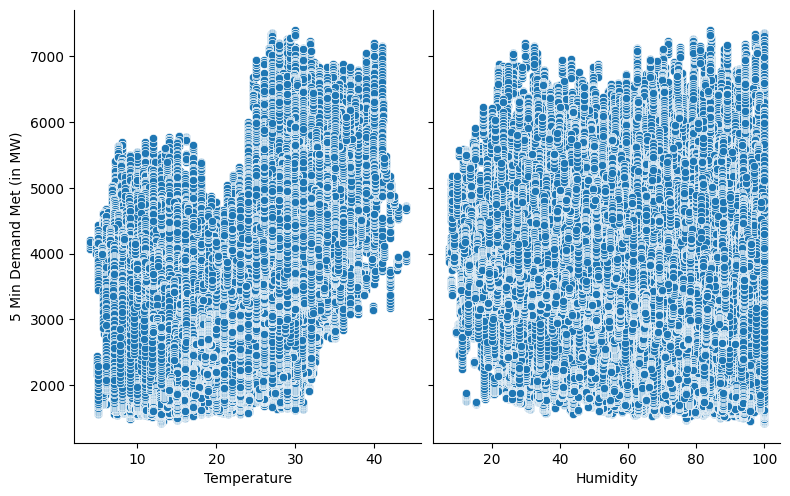

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

season_mapping = {
    'Winter': 0,
    'Summer': 1,
    'Rainy': 2,
    'Autumn': 3
}

df['Season'] = df['Season'].map(season_mapping)
# Pairplot for visualizing relationships
sns.pairplot(df, x_vars=['Temperature', 'Humidity'], y_vars='5 Min Demand Met (in MW)', height=5, aspect=0.8)
plt.show()

In [45]:
df.tail()

,Date,Time,5 Min Demand Met (in MW),Season,Temperature,Humidity
134203,2024-04-30,1900-04-21 14:10:00,4822.94,1,26.0,41.73
134204,2024-04-30,1900-04-21 14:15:00,4823.10,1,26.0,41.73
134205,2024-04-30,1900-04-21 14:20:00,4818.51,1,27.9,50.23
134206,2024-04-30,1900-04-21 14:25:00,4815.28,1,27.9,50.23
134207,2024-04-30,1900-04-21 14:30:00,4818.21,1,27.9,50.23


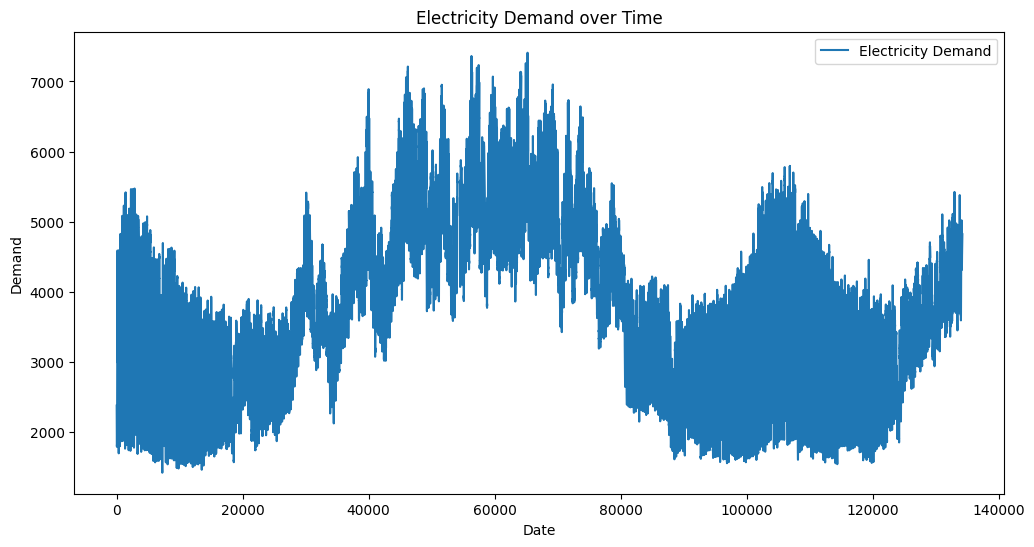

In [46]:
plt.figure(figsize=(12,6))
plt.plot(df['5 Min Demand Met (in MW)'], label='Electricity Demand')
plt.title('Electricity Demand over Time')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.show()


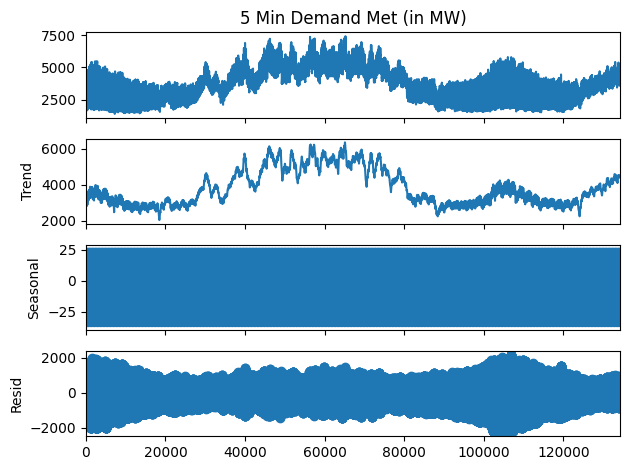

In [47]:
# Decompose the time series
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(df['5 Min Demand Met (in MW)'], model='additive', period=365)
decomposition.plot()
plt.show()

In [50]:
# Perform stationarity test (ADF test)
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['5 Min Demand Met (in MW)'])
if result[1] <= 0.05 :
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
else:
    print('Grester than 0.05')

ADF Statistic: -13.972231005879644
p-value: 4.324446098307547e-26


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134208 entries, 0 to 134207
Data columns (total 6 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Date                      134208 non-null  datetime64[ns]
 1   Time                      134208 non-null  object        
 2   5 Min Demand Met (in MW)  134208 non-null  float64       
 3   Season                    134208 non-null  int64         
 4   Temperature               134208 non-null  float64       
 5   Humidity                  134208 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(1)
memory usage: 6.1+ MB


# SARIMAX model

In [52]:
df.head()

,Date,Time,5 Min Demand Met (in MW),Season,Temperature,Humidity
0,2023-01-01,00:00:00,2377.87,0,12.4,93.58
1,2023-01-01,00:05:00,2327.74,0,12.4,93.58
2,2023-01-01,00:10:00,2297.35,0,12.4,93.58
3,2023-01-01,00:15:00,2287.87,0,12.4,93.58
4,2023-01-01,00:20:00,2243.37,0,12.4,93.58


In [53]:
import numpy as np
from pmdarima import auto_arima

import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import MinMaxScaler
# Assuming df is your original DataFrame with the Demand column
# Select relevant features, normalizing only specific columns
exog_vars = df[['Humidity', 'Temperature', 'Season']]

# Initialize the StandardScaler
scaler = MinMaxScaler()

# Normalize only the 'Humidity', 'Temperature', and 'Wind Speed' columns
exog_vars[['Humidity', 'Temperature', 'Season']] = scaler.fit_transform(exog_vars[['Humidity', 'Temperature', 'Season']])
'''
model = auto_arima(df['Demand'], seasonal=True, m=12,
                   exogenous=exog_vars,
                   stepwise=True, trace=True)
'''
train_data = df['5 Min Demand Met (in MW)'][:-365]   # Exclude last 365 rows for training
test_data = df['5 Min Demand Met (in MW)'][-365:]    # Last 365 rows for testing

# Split the exogenous variables as well, if you have them
train_exog = exog_vars[:-365]
test_exog = exog_vars[-365:]

    
# Fit the SARIMAX model with the updated exogenous variables
model = SARIMAX(df['5 Min Demand Met (in MW)'], order=(0, 2, 1), seasonal_order=(0, 0, 0, 12), exog=exog_vars)
model_fit = model.fit()

C:\Users\rupes\AppData\Local\Temp\ipykernel_400\489843844.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exog_vars[['Humidity', 'Temperature', 'Season']] = scaler.fit_transform(exog_vars[['Humidity', 'Temperature', 'Season']])


In [54]:
len(df)

134208

In [55]:
# Make predictions
df['SARIMAX_Predictions'] = model_fit.predict(start=len(train_data),end=len(train_data) + len(test_data) - 1, exog=test_exog)

# Shift predictions to align with actual values
df['SARIMAX_Predictions'] = df['SARIMAX_Predictions'].shift(-1)

# Drop NaN values after shifting
df = df.dropna()

# Evaluate the model
predictions = df['SARIMAX_Predictions']
actual = df['5 Min Demand Met (in MW)']

# Calculate and print evaluation metrics
mae = mean_absolute_error(actual, predictions)
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(actual, predictions)
r2 = r2_score(actual, predictions)

print(f'MAE: {mae}, MSE: {mse}, RMSE: {rmse}, MAPE: {mape * 100:.2f}%, R2: {r2}')

MAE: 13.073543685618663, MSE: 237.40365069244808, RMSE: 15.407908706000567, MAPE: 0.29%, R2: 0.9986161206222703


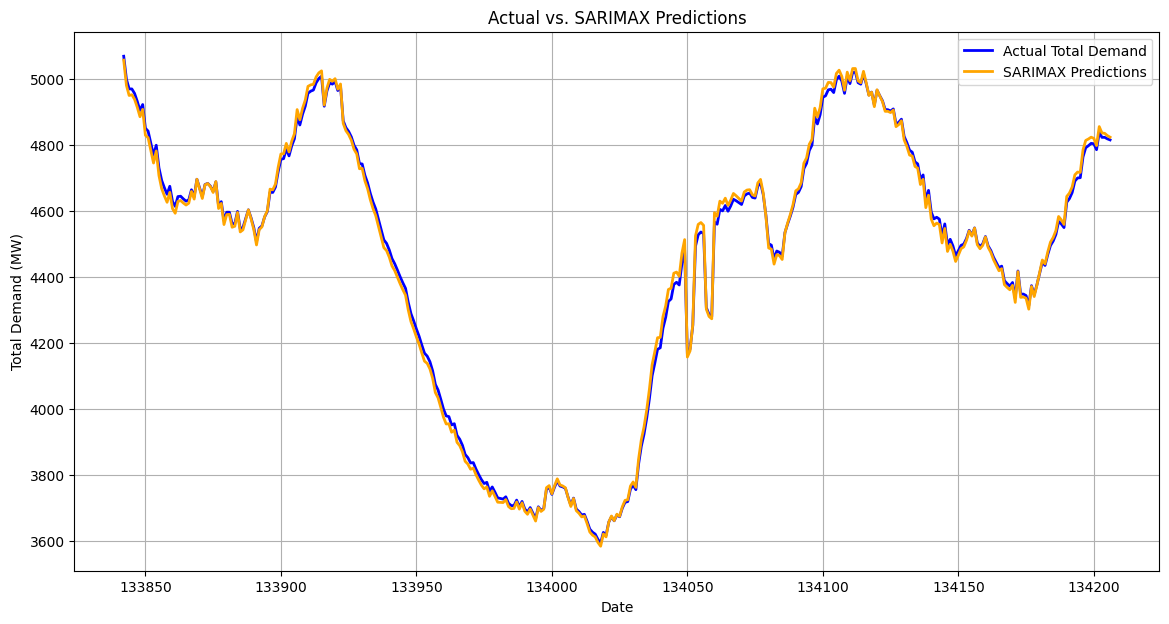

In [56]:
import matplotlib.pyplot as plt

#actual = df['Demand']
#predictions = df['SARIMAX_Predictions']

plt.figure(figsize=(14, 7))
plt.plot(actual.index, actual, label='Actual Total Demand', color='blue', linewidth=2)
plt.plot(predictions.index, predictions, label='SARIMAX Predictions', color='orange', linewidth=2)
plt.title('Actual vs. SARIMAX Predictions')
plt.xlabel('Date')
plt.ylabel('Total Demand (MW)')
plt.legend()
plt.grid()
plt.show()

In [57]:
df["SARIMAX_Predictions"]

133842    5057.086173
133843    4980.530680
133844    4949.862520
133845    4952.197463
133846    4938.414495
             ...     
134202    4855.653075
134203    4836.217798
134204    4835.264093
134205    4828.267359
134206    4823.506782
Name: SARIMAX_Predictions, Length: 365, dtype: float64

In [58]:
print(df)

             Date                 Time  5 Min Demand Met (in MW)  Season  \
133842 2024-04-29  1900-04-20 08:05:00                   5068.90       1   
133843 2024-04-29  1900-04-20 08:10:00                   4999.17       1   
133844 2024-04-29  1900-04-20 08:15:00                   4969.77       1   
133845 2024-04-29  1900-04-20 08:20:00                   4969.76       1   
133846 2024-04-29  1900-04-20 08:25:00                   4956.14       1   
...           ...                  ...                       ...     ...   
134202 2024-04-30  1900-04-21 14:05:00                   4838.52       1   
134203 2024-04-30  1900-04-21 14:10:00                   4822.94       1   
134204 2024-04-30  1900-04-21 14:15:00                   4823.10       1   
134205 2024-04-30  1900-04-21 14:20:00                   4818.51       1   
134206 2024-04-30  1900-04-21 14:25:00                   4815.28       1   

        Temperature  Humidity  SARIMAX_Predictions  
133842         29.0     32.77     

In [59]:
df.head()

,Date,Time,5 Min Demand Met (in MW),Season,Temperature,Humidity,SARIMAX_Predictions
133842,2024-04-29,1900-04-20 08:05:00,5068.90,1,29.0,32.77,5057.086173
133843,2024-04-29,1900-04-20 08:10:00,4999.17,1,29.0,32.77,4980.530680
133844,2024-04-29,1900-04-20 08:15:00,4969.77,1,29.0,32.77,4949.862520
133845,2024-04-29,1900-04-20 08:20:00,4969.76,1,29.0,32.77,4952.197463
133846,2024-04-29,1900-04-20 08:25:00,4956.14,1,29.0,32.77,4938.414495


In [61]:
# Assuming 'actual' and 'predictions' are defined and have the same length as the sliced dates
df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0], errors='coerce')  # Convert to datetime

results_df = pd.DataFrame({
    'Date': df["Date"],
    "Time": df["Time"],
    'Actual': actual,
    'Predicted': predictions
})

In [62]:
results_df[:365]

,Date,Time,Actual,Predicted
133842,2024-04-29,1900-04-20 08:05:00,5068.90,5057.086173
133843,2024-04-29,1900-04-20 08:10:00,4999.17,4980.530680
133844,2024-04-29,1900-04-20 08:15:00,4969.77,4949.862520
133845,2024-04-29,1900-04-20 08:20:00,4969.76,4952.197463
133846,2024-04-29,1900-04-20 08:25:00,4956.14,4938.414495
...,...,...,...,...
134202,2024-04-30,1900-04-21 14:05:00,4838.52,4855.653075
134203,2024-04-30,1900-04-21 14:10:00,4822.94,4836.217798
134204,2024-04-30,1900-04-21 14:15:00,4823.10,4835.264093
134205,2024-04-30,1900-04-21 14:20:00,4818.51,4828.267359


In [63]:
df2 = pd.DataFrame(results_df[['Actual','Predicted']])
df2['diff'] = df2['Actual'] - df2['Predicted']
df2

,Actual,Predicted,diff
133842,5068.90,5057.086173,11.813827
133843,4999.17,4980.530680,18.639320
133844,4969.77,4949.862520,19.907480
133845,4969.76,4952.197463,17.562537
133846,4956.14,4938.414495,17.725505
...,...,...,...
134202,4838.52,4855.653075,-17.133075
134203,4822.94,4836.217798,-13.277798
134204,4823.10,4835.264093,-12.164093
134205,4818.51,4828.267359,-9.757359


In [64]:
df2.to_csv("5 Min Output2.csv")

Saving Model

In [65]:
import pickle
with open('5Min-model2.pkl', 'wb') as f:
    pickle.dump(model_fit, f, protocol=4)  # Use protocol 4+ for efficient saving


In [66]:
import pickle
import pandas as pd

# Load the saved SARIMAX model
with open('5Min-model.pkl', 'rb') as f:
    model_fit = pickle.load(f)

# Function to take manual inputs and make predictions
def predict_demand():
    try:
        # Take manual inputs
        humidity = float(input("Enter Humidity (%): "))
        temperature = float(input("Enter Temperature (°C): "))
        season = int(input("Enter Season (1-Winter, 2-Summer, 3-Rainy, 4-Autumn): "))

        # Create a DataFrame for input
        input_data = pd.DataFrame([[humidity, temperature, season]], columns=['Humidity', 'Temperature', 'Season'])

        # Predict demand for the next time step
        prediction = model_fit.predict(start=len(model_fit.data.endog), end=len(model_fit.data.endog), exog=input_data)

        print(f"Predicted Electricity Demand: {prediction.iloc[0]:.2f} MW")

    except Exception as e:
        print(f"Error: {e}")

# Call the function to make predictions
predict_demand()


Predicted Electricity Demand: 5158.78 MW


In [71]:
import pandas as pd
import numpy as np
import requests
import pickle
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# Your API Key
api_key = "DUS2HREYY2L7ZVCLY7SKDXYDZ"

# Base URL for the Visual Crossing Weather API
base_url = "https://weather.visualcrossing.com/VisualCrossingWebServices/rest/services/timeline"


In [72]:
# Function to fetch 5-minute interval weather data for a given location and date
def fetch_weather_data(location, date):
    params = {
        "unitGroup": "metric",
        "key": api_key,
        "contentType": "json"
    }
    
    url = f"{base_url}/{location}/{date}"
    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()
        try:
            if "days" in data:
                day_data = data["days"][0]
                hourly_data = day_data.get("hours", [])
                
                timestamps, temperatures, humidities, conditions = [], [], [], []
                for hour in hourly_data:
                    hour_time = pd.to_datetime(f"{date} {hour['datetime']}")
                    for minute in range(0, 60, 5):  # Generating 5-minute intervals
                        timestamps.append(hour_time + pd.Timedelta(minutes=minute))
                        temperatures.append(hour["temp"])
                        humidities.append(hour["humidity"])
                        conditions.append(hour["conditions"])
                
                weather_df = pd.DataFrame({
                    "Date": [t.date() for t in timestamps],
                    "Time": [t.time() for t in timestamps],
                    "Temperature": temperatures,
                    "Humidity": humidities,
                    "Conditions": conditions
                })
                return weather_df
            else:
                print("Error: 'days' field is missing in the API response.")
                return None
        except KeyError as e:
            print(f"KeyError: {e} - Check if the response structure has changed.")
            return None
    else:
        print(f"Failed to fetch data. HTTP Status code: {response.status_code}")
        return None


In [73]:
# Function to preprocess 5-minute dataset
def prepare_5min_data(df):
    df['Date'] = pd.to_datetime(df['Date'])
    
    # Season mapping based on dataset format
    def determine_season(temp):
        if temp <= 15:
            return 'Winter'
        elif temp <= 25:
            return 'Autumn'
        elif temp <= 30:
            return 'Summer'
        else:
            return 'Rainy'
    
    df['Season'] = df['Temperature'].apply(determine_season)
    
    season_mapping = {'Winter': 0, 'Summer': 1, 'Rainy': 2, 'Autumn': 3}
    df['Season'] = df['Season'].map(season_mapping).fillna(-1)
    
    scaler = MinMaxScaler()
    df[['Humidity', 'Temperature', 'Season']] = scaler.fit_transform(df[['Humidity', 'Temperature', 'Season']])
    
    return df

# Function to load the SARIMAX model
def load_model(model_path):
    return joblib.load(model_path)

# Function to predict future demand using 5-minute model
def predict_future_demand_5min(location, future_date, model_path):
    weather_df = fetch_weather_data(location, future_date)
    
    if weather_df is not None:
        weather_df = prepare_5min_data(weather_df)
        future_exog = weather_df[['Temperature', 'Humidity', 'Season']]
        
        model_fit = load_model(model_path)
        future_predictions = model_fit.predict(start=0, end=len(weather_df)-1, exog=future_exog)
        
        weather_df['Predicted Demand (MW)'] = future_predictions
        
        print(f"Predicted 5-Minute Interval Demand for {location} on {future_date}:")
        print(weather_df[['Date', 'Time', 'Predicted Demand (MW)']])
        
        plt.figure(figsize=(12, 6))
        plt.plot(weather_df['Time'], weather_df['Predicted Demand (MW)'], marker='o', color='b', label='Predicted Demand (MW)')
        plt.title(f'Predicted 5-Minute Electricity Demand for {location} on {future_date}')
        plt.xlabel('Time')
        plt.ylabel('Predicted Demand (MW)')
        plt.xticks(rotation=45)
        plt.legend()
        plt.grid()
        plt.tight_layout()
        plt.show()

Predicted 5-Minute Interval Demand for Delhi on 2025-02-20:
          Date      Time  Predicted Demand (MW)
0   2025-02-20  00:00:00               1.133537
1   2025-02-20  00:05:00            3566.250991
2   2025-02-20  00:10:00            2280.979179
3   2025-02-20  00:15:00            2258.827548
4   2025-02-20  00:20:00            2259.270286
..         ...       ...                    ...
283 2025-02-20  23:35:00            2357.544248
284 2025-02-20  23:40:00            2325.376121
285 2025-02-20  23:45:00            2164.604343
286 2025-02-20  23:50:00            2108.024387
287 2025-02-20  23:55:00            2105.509266

[288 rows x 3 columns]


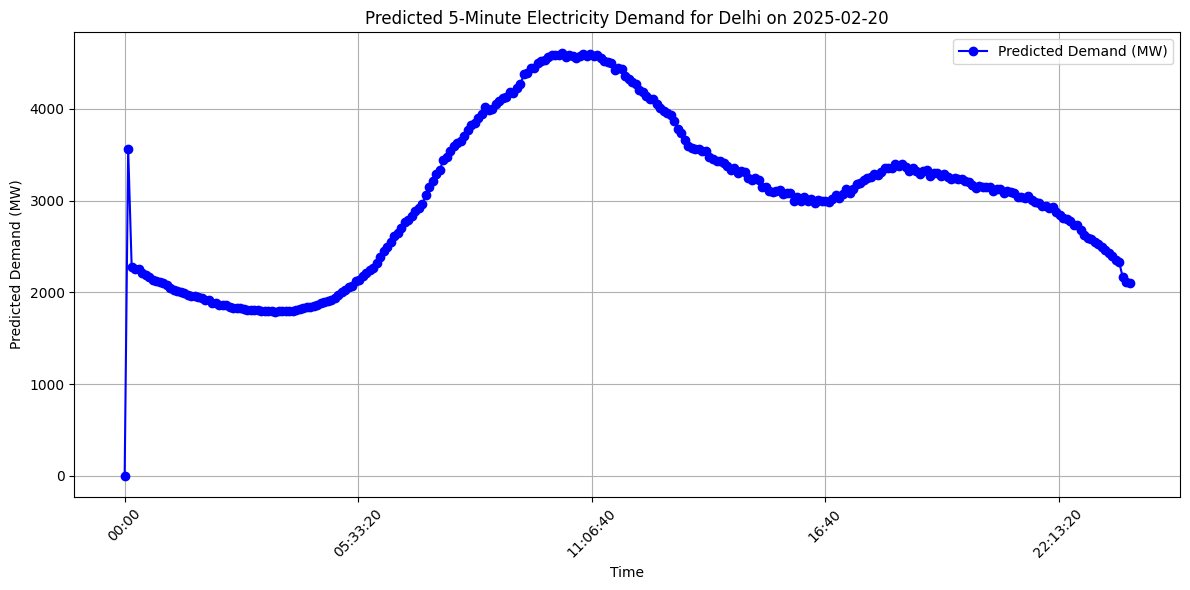

In [74]:
# User input
location = "Delhi"
date = input("Enter date (YYYY-MM-DD): ")
model_path = "5Min-model2.pkl"

# Predict 5-minute interval demand
predict_future_demand_5min(location, date, model_path)